# Actividad 5.3 — Simulación Monte Carlo de inventarios EOQ

## Parte 1: análisis estadístico de la demanda diaria

**Fuente:** `5.3.- demanda_simulada_tres_ubicaciones_mexico.xlsx` (mismo repositorio).

**Objetivo de esta primera etapa:** partir de los registros de **pedidos individuales**, sumar la demanda de cada ciudad y fecha, y construir las estadísticas y frecuencias relativas acumuladas que utilizaremos en Monte Carlo.

**Importante:** el Excel tiene tres hojas: «Demanda simulada», «Resumen por ubicación» y «Diccionario de datos». **La demanda diaria se obtiene de «Demanda simulada»**, no de los totales de «Resumen por ubicación».

El diccionario indica que los registros abarcan del **1 de enero al 10 de octubre de 2026**, un periodo menor a un año. Para EOQ necesitaremos posteriormente definir cómo estimar la demanda anual D o conseguir un año completo.

**Alcance:** carga de datos, construcción de totales diarios, estadísticas, frecuencias y gráficos. **Todavía no simularemos días futuros ni calcularemos EOQ, ROP o SS.**

## Paso 1. Cargar las bibliotecas

Usamos `pandas` para tablas, `numpy` para operaciones numéricas, `matplotlib` para visualizar los resultados y `display` para mostrar las tablas en Jupyter.

`read_excel()` abrirá el libro que está guardado en la **misma carpeta** que este notebook.

In [7]:
from pathlib import Path
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

## Paso 2. Examinar las hojas y sus columnas

Primero verificamos la estructura del libro. La hoja correcta para estudiar la demanda es **«Demanda simulada»**, que contiene:
- `Cantidad demandada`: unidades de cada pedido.
- `Fecha del pedido`: fecha del pedido.
- `Ubicación`: ciudad.

Una ciudad puede tener **varios pedidos el mismo día**. Por eso hay que sumarlos antes de analizar la demanda diaria.

In [8]:
ARCHIVO = Path("5.3.- demanda_simulada_tres_ubicaciones_mexico.xlsx")

if not ARCHIVO.is_file():
    raise FileNotFoundError(
        f"No encuentro {ARCHIVO.name} en {Path.cwd()}. "
        "Abre el notebook en la carpeta raíz del repositorio y ejecuta git pull."
    )

hojas = pd.read_excel(ARCHIVO, sheet_name=None)

print(f"Archivo: {ARCHIVO.name}")
print(f"Hojas detectadas: {list(hojas)}")

for nombre_hoja, df in hojas.items():
    print(f"\nHOJA: {nombre_hoja}")
    print(f"Filas: {len(df)} | Columnas: {list(df.columns)}")
    display(df.head(5))

Archivo: 5.3.- demanda_simulada_tres_ubicaciones_mexico.xlsx
Hojas detectadas: ['Demanda simulada', 'Resumen por ubicación', 'Diccionario de datos']

HOJA: Demanda simulada
Filas: 1200 | Columnas: ['Cantidad demandada', 'Fecha del pedido', 'Ubicación']


,Cantidad demandada,Fecha del pedido,Ubicación
0,41,2026-01-01,Guadalajara
1,33,2026-01-01,Monterrey
2,54,2026-01-01,Monterrey
3,45,2026-01-02,Ciudad de México
4,33,2026-01-02,Ciudad de México



HOJA: Resumen por ubicación
Filas: 3 | Columnas: ['Ubicación', 'Número de pedidos', 'Demanda total', 'Demanda promedio', 'Demanda mínima', 'Demanda máxima']


,Ubicación,Número de pedidos,Demanda total,Demanda promedio,Demanda mínima,Demanda máxima
0,Ciudad de México,424,17875,42.158019,9,81
1,Guadalajara,408,12136,29.745098,1,54
2,Monterrey,368,13262,36.038043,1,68



HOJA: Diccionario de datos
Filas: 6 | Columnas: ['Campo', 'Descripción']


,Campo,Descripción
0,Cantidad demandada,Unidades demandadas en cada pedido; valores en...
1,Fecha del pedido,Fecha simulada del pedido.
2,Ubicación,"Una de tres ubicaciones: Ciudad de México, Gua..."
3,Número de registros,"1200 pedidos simulados (más de 1,000)."
4,Periodo simulado,Del 01/01/2026 al 10/10/2026.


## Paso 3. Convertir pedidos individuales en demanda diaria por ciudad

Esta es la corrección fundamental respecto a la primera versión del notebook.

Por ejemplo, si Monterrey recibió dos pedidos el 1 de enero, de 33 y 54 unidades, **su demanda diaria es 87 unidades**, no dos días separados.

Agrupamos con `groupby(["Ciudad", "Fecha"]).sum()`. Después generamos una fecha por cada día del periodo estudiado y cada ciudad.

**Supuesto explícito:** consideramos que la hoja registra todos los pedidos realizados en el periodo. Entonces, un día sin pedidos registrados tiene demanda cero. Si el archivo contiene días sin información por otra razón (faltantes o cierres sin registro), habría que tratarlos de otra manera.

Usaremos **días calendario** en esta primera etapa y comprobaremos si el archivo cubre un año completo.

In [9]:
# Usamos los pedidos individuales, no el resumen agregado.
pedidos = hojas["Demanda simulada"].copy()

columnas_necesarias = {"Cantidad demandada", "Fecha del pedido", "Ubicación"}
faltantes = columnas_necesarias - set(pedidos.columns)
if faltantes:
    raise ValueError(f"Faltan columnas en 'Demanda simulada': {faltantes}")

pedidos = pedidos.rename(columns={
    "Cantidad demandada": "Demanda",
    "Fecha del pedido": "Fecha",
    "Ubicación": "Ciudad",
})

# Convertir fecha, demanda y ciudad a tipos consistentes.
pedidos["Fecha"] = pd.to_datetime(pedidos["Fecha"], errors="coerce").dt.normalize()
pedidos["Demanda"] = pd.to_numeric(pedidos["Demanda"], errors="coerce")
pedidos["Ciudad"] = pedidos["Ciudad"].astype("string").str.strip()

if pedidos[["Fecha", "Demanda", "Ciudad"]].isna().any().any():
    raise ValueError("Hay pedidos con fecha, ciudad o demanda faltante o inválida.")
if (pedidos["Demanda"] < 0).any():
    raise ValueError("Hay demandas negativas: verifica su significado.")
if not np.allclose(pedidos["Demanda"], pedidos["Demanda"].round()):
    raise ValueError("Hay cantidades no enteras: comprueba las unidades.")

pedidos["Demanda"] = pedidos["Demanda"].astype(int)
if (pedidos["Ciudad"] == "").any():
    raise ValueError("Hay nombres de ciudad vacíos.")

# La suma diaria por ciudad reúne múltiples pedidos del mismo día.
totales_por_dia = (
    pedidos.groupby(["Ciudad", "Fecha"], as_index=False, observed=True)["Demanda"].sum()
)

# Completamos días sin pedidos con demanda cero, bajo el supuesto explicado arriba.
ciudades = sorted(pedidos["Ciudad"].unique().tolist())
calendario = pd.date_range(
    pedidos["Fecha"].min(), pedidos["Fecha"].max(), freq="D"
)
indice_completo = pd.MultiIndex.from_product(
    [ciudades, calendario], names=["Ciudad", "Fecha"]
)

demanda_diaria = (
    totales_por_dia.set_index(["Ciudad", "Fecha"])["Demanda"]
    .reindex(indice_completo, fill_value=0)
    .rename("Demanda")
    .reset_index()
)

print("Ciudades:", ciudades)
print("Pedidos individuales:", len(pedidos))
print(f"Periodo: {calendario.min().date()} a {calendario.max().date()}")
print("Días calendario en el periodo:", len(calendario))
print("Observaciones diarias por ciudad:", len(demanda_diaria) // len(ciudades))

print("\nEjemplo: primeras observaciones diarias")
display(demanda_diaria.head(12))

# Comprobación: al agrupar por día NO se deben perder ni duplicar unidades.
suma_pedidos = pedidos.groupby("Ciudad")["Demanda"].sum().sort_index()
suma_diaria = demanda_diaria.groupby("Ciudad")["Demanda"].sum().sort_index()
assert suma_pedidos.equals(suma_diaria), "Error: los totales diarios no coinciden con los pedidos."

# El resumen del Excel se utiliza solo para validar los totales, nunca como demanda diaria.
resumen_excel = hojas["Resumen por ubicación"].set_index("Ubicación")["Demanda total"]
resumen_excel = pd.to_numeric(resumen_excel, errors="raise").sort_index()
assert suma_diaria.equals(resumen_excel), "Los totales no coinciden con la hoja resumen."

if len(ciudades) != 3:
    print("ADVERTENCIA: la actividad pide exactamente tres ciudades.")

if len(calendario) < 365:
    print(
        "\nADVERTENCIA: no hay un año completo de demanda diaria. "
        "Más adelante se debe justificar cómo estimar D anual para EOQ."
    )

print("\nTotales por ciudad verificados contra el resumen del Excel:")
display(suma_diaria.rename("Unidades totales registradas").to_frame())

Resumen por ubicación: formato largo (Ciudad=Ubicación, Demanda=Demanda total).
Hojas omitidas por no reconocer datos de demanda: ['Demanda simulada', 'Diccionario de datos']

Vista de los datos estandarizados:


,Ciudad,Demanda
0,Ciudad de México,17875
1,Guadalajara,12136
2,Monterrey,13262



Observaciones por ciudad:


,Días registrados
Ciudad,
Ciudad de México,1
Guadalajara,1
Monterrey,1


## Paso 4. Estadísticas descriptivas **de la demanda diaria**

Ahora que agrupamos los pedidos por día, calculamos para cada ciudad:

- Días del periodo analizado.
- Media de unidades **por día**.
- Desviación estándar diaria.
- Demanda mínima, máxima y total **registrada en el periodo**.
- Número de días con demanda cero.

**No confundas** el promedio de unidades *por pedido* de la hoja «Resumen por ubicación» con el promedio de unidades *por día* que necesitamos para Monte Carlo y el cálculo del ROP.

La actividad solicita demanda **anual** para EOQ, pero el archivo que tenemos todavía abarca menos de un año. No etiquetaremos el total del periodo como anual.

In [10]:
resumen = (
    demanda_diaria.groupby("Ciudad")["Demanda"]
    .agg(
        Dias_registrados="count",
        Demanda_media_diaria="mean",
        Desviacion_estandar_diaria="std",
        Demanda_minima_diaria="min",
        Demanda_maxima_diaria="max",
        Demanda_total_periodo="sum",
        Dias_demanda_cero=lambda s: (s == 0).sum(),
    )
    .reset_index()
)

print("Resumen estadístico de DEMANDA DIARIA (no de pedidos individuales)")
display(resumen.round(2))
print(
    "\nIMPORTANTE: 'Demanda_total_periodo' no es demanda anual "
    "si no contamos con un año completo de información."
)

,Ciudad,Dias_registrados,Demanda_media,Desviacion_estandar,Demanda_minima,Demanda_maxima,Demanda_total,Dias_demanda_cero
0,Ciudad de México,1,17875.0,NaN,17875,17875,17875,0
1,Guadalajara,1,12136.0,NaN,12136,12136,12136,0
2,Monterrey,1,13262.0,NaN,13262,13262,13262,0


Recuerda: para interpretar 'Demanda_total' como anual, confirma que el Excel
contenga el año completo en cada ciudad.


## Paso 5. Frecuencias relativas acumuladas de la demanda diaria

Para cada ciudad contamos cuántos días se registró cada nivel de demanda diaria (ya sumados los pedidos del día).

- **Frecuencia absoluta:** cantidad de días con esa demanda.
- **Frecuencia relativa:** frecuencia absoluta dividida entre días estudiados.
- **Frecuencia acumulada:** suma de las frecuencias absolutas.
- **Frecuencia relativa acumulada:** suma de las frecuencias relativas hasta alcanzar 1.

Estas son las distribuciones empíricas que utilizaremos para convertir un número U(0,1) en demanda diaria simulada.

Ejemplo: si la acumulada pasa de 0.30 para 10 unidades a 0.70 para 20 unidades, U = 0.56 produce demanda de 20 unidades.

Las tablas pueden ser extensas porque aquí utilizamos cada valor de demanda, sin agrupar por intervalos.

In [11]:
tablas_frecuencia = {}

for ciudad, grupo in demanda_diaria.groupby("Ciudad"):
    tabla = (
        grupo["Demanda"]
        .value_counts()
        .sort_index()
        .rename_axis("Demanda")
        .reset_index(name="Frecuencia absoluta")
    )

    total_dias = int(tabla["Frecuencia absoluta"].sum())
    tabla["Frecuencia relativa"] = tabla["Frecuencia absoluta"] / total_dias
    tabla["Frecuencia acumulada"] = tabla["Frecuencia absoluta"].cumsum()
    tabla["Frecuencia relativa acumulada"] = tabla["Frecuencia relativa"].cumsum()

    tablas_frecuencia[ciudad] = tabla

    print(f"\n{ciudad}: {total_dias} días, {len(tabla)} niveles distintos de demanda.")
    display(tabla.round(5))

    assert tabla["Frecuencia absoluta"].sum() == total_dias
    assert np.isclose(tabla["Frecuencia relativa"].sum(), 1.0)
    assert np.isclose(tabla["Frecuencia relativa acumulada"].iloc[-1], 1.0)

print("\nTodas las distribuciones empíricas suman 100%.")


TABLA DE FRECUENCIAS: Ciudad de México (1 días)


,Demanda,Frecuencia absoluta,Frecuencia relativa,Frecuencia acumulada,Frecuencia relativa acumulada
0,17875,1,1.0,1,1.0



TABLA DE FRECUENCIAS: Guadalajara (1 días)


,Demanda,Frecuencia absoluta,Frecuencia relativa,Frecuencia acumulada,Frecuencia relativa acumulada
0,12136,1,1.0,1,1.0



TABLA DE FRECUENCIAS: Monterrey (1 días)


,Demanda,Frecuencia absoluta,Frecuencia relativa,Frecuencia acumulada,Frecuencia relativa acumulada
0,13262,1,1.0,1,1.0



Comprobación: todas las frecuencias relativas acumuladas terminan en 1.


## Paso 6. Histogramas de la demanda diaria

Ahora graficaremos **unidades demandadas por día** (no unidades por pedido ni totales por ciudad).

En el siguiente paso de la actividad tomaremos los números uniformes U y utilizaremos las frecuencias acumuladas calculadas aquí para generar demandas sintéticas que respeten la distribución empírica de cada ciudad.

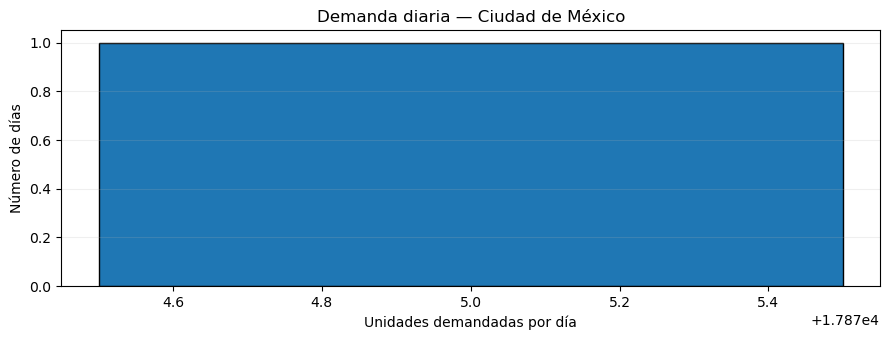

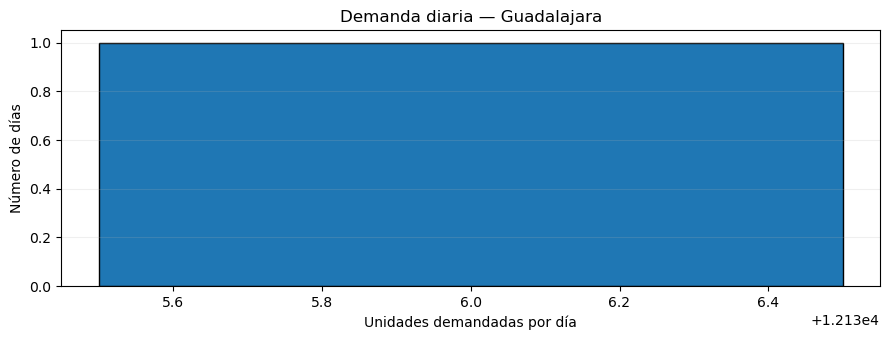

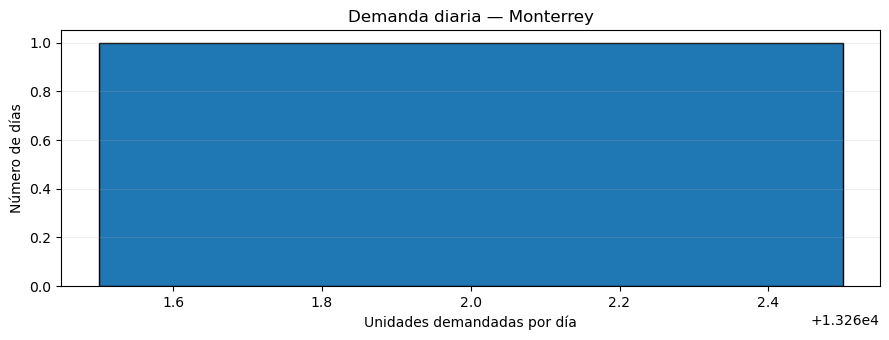

In [12]:
for ciudad, grupo in demanda_diaria.groupby("Ciudad"):
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.hist(grupo["Demanda"], bins="auto", edgecolor="black")
    ax.set_title(f"Demanda diaria — {ciudad}")
    ax.set_xlabel("Unidades demandadas por día")
    ax.set_ylabel("Número de días")
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()

## Resumen y siguiente parte

**Ya tenemos:**
1. Pedidos individuales agrupados por ciudad y día.
2. Series diarias con días sin pedidos completados como cero, suponiendo que el archivo está completo.
3. Resumen estadístico diario.
4. Frecuencias absolutas, relativas y acumuladas por ciudad.
5. Histogramas diarios.

**Limitación a resolver:** el Excel abarca un periodo menor a un año. Para el EOQ clásico hace falta la demanda anual (D). En la etapa siguiente habrá que elegir **obtener 12 meses de datos** o estimarla con una **proyección explícitamente justificada**. También necesitaremos el costo por pedido (S), el costo anual de mantener (H), el plazo de entrega (L), el inventario inicial y el nivel de servicio (para SS).

**Todavía no hemos generado nuevos valores aleatorios.** Eso se hará después de preparar y validar estas tablas, mediante la transformación discreta por frecuencia acumulada.